# Image → Gabor directions → fitted line field

A short workflow using ordinary files in this project. Read and run the cells from top to bottom.
Choose one of the six comparison images or either SEM below. Change a parameter and rerun the following cells.
The only interactive widgets inspect a Gabor response and an archived fitted field.

**Workflow:** load image → binary mask → Gabor energies → measured peaks → smoothness-based selection → fit four models → plot results.

All numerical implementations are written below, beside the stage that uses them. Only standard scientific Python libraries are imported. The image and saved-result files remain ordinary files under `data/` and `output/`; no data is embedded in code.


## 1. Imports and image choice

Open Jupyter beside the `data/` and `output/` folders, or in `python_notebooks/`. Dependencies: NumPy, SciPy, pandas, Pillow, Matplotlib, and ipywidgets. No project modules or helper scripts are needed to run the notebook.


In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import PowerNorm
from PIL import Image
from ipywidgets import interact, IntSlider
from IPython.display import display
from scipy import ndimage
from scipy.signal import fftconvolve
from scipy.linalg import cho_factor, cho_solve
from scipy.spatial.distance import cdist
from scipy.optimize import minimize
from scipy.special import i0e, i1e

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
if not (ROOT / "data").exists():
    raise FileNotFoundError("Set ROOT to the folder containing data/ and output/.")


In [2]:
# Change this name, then rerun the cells below.
image = "shell"

original_inputs = ROOT / "data/mse_full_image_revision_20261021/inputs"
revised_inputs = ROOT / "data/mse_rosette_mask_revision_20261022/inputs"
sem_inputs = ROOT / "data/sem_front_revision_20261104/inputs"
input_files = {
    "shell": original_inputs / "shell.npz",
    "fern": original_inputs / "fern.npz",
    "particle_fig5": original_inputs / "particle_fig5.npz",
    "particle_fig27": original_inputs / "particle_fig27.npz",
    "rosette_ppt_13": revised_inputs / "rosette_ppt_13.npz",
    "rosette_ppt_14": original_inputs / "rosette_ppt_14.npz",
    "front_ee_minus1_5_1500x": sem_inputs / "front_ee_minus1_5_1500x.npz",
    "front_ee1_3_1500x": sem_inputs / "front_ee1_3_1500x.npz",
}
with np.load(input_files[image]) as source:
    rgb = source["rgb"]
    approved_mask = source["mask"].astype(bool)
    center = source["center_px"]
    scale = float(source["scale_px"])
gray = np.asarray(Image.fromarray(rgb).convert("L"), float) / 255
print(image, "· working image:", rgb.shape[:2], "· center:", center)


shell · working image: (340, 339) · center: [152.84393064 149.73076923]


## 2. Binary mask

The approved mask is a saved, image-only segmentation. Different images required different segmentation rules; this cell loads that mask rather than claiming to recreate those choices with a common threshold. All Gabor queries and fits below are recomputed.

For a simple masking experiment, uncomment the threshold line. It restricts the approved domain and preserves its existing exclusions. Such a change starts a new exploratory analysis; archived results later retain the approved mask.


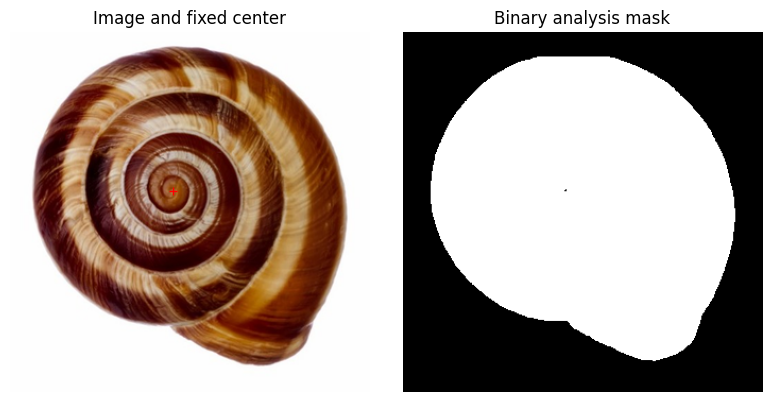

In [3]:
mask = approved_mask.copy()
# mask = approved_mask & (gray < 0.65)  # Optional dark-texture threshold.

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(rgb)
axes[0].plot(*center, "r+")
axes[0].set_title("Image and fixed center")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Binary analysis mask")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 3. Sample positions and compute Gabor energies

Sample 305 mask pixels before inspecting their responses. No-candidate sites are counted later and are not replaced.
The bank contains 36 normal orientations, using normalized cosine/sine filters, wavelength 6 working pixels, and one-pixel energy smoothing.


The filter calculation is explicit: rotate an elongated Gaussian, multiply by sine and cosine, normalize each filter, convolve, then add the two squared responses.


In [4]:
def gabor_energy(
    values: np.ndarray,
    wavelength: float = 6.0,
    angle_count: int = 36,
    energy_sigma: float = 1.0,
) -> np.ndarray:
    """Return normal-orientation quadrature energies as (angle, y, x).

    Bins span [0, pi). Zero-mean, unit-norm quadrature filters suppress the
    constant image component and give comparable energies across orientations.
    A small spatial average of energy reduces interference at texture crossings.
    Input pixel intensities should be scaled to [0, 1].
    """
    values = np.asarray(values, dtype=float)
    if values.ndim != 2 or not values.size or not np.all(np.isfinite(values)):
        raise ValueError("Gabor extraction requires a finite, nonempty grayscale image.")
    if not np.isfinite(wavelength) or wavelength <= 0:
        raise ValueError("Gabor wavelength must be positive and finite.")
    if not isinstance(angle_count, (int, np.integer)) or angle_count < 8:
        raise ValueError("At least eight Gabor orientation bins are required.")
    if not np.isfinite(energy_sigma) or energy_sigma < 0:
        raise ValueError("Energy smoothing must be nonnegative and finite.")

    sigma, gamma = 3.2, 0.5
    # Include three standard deviations along the elongated kernel axis.
    radius = int(np.ceil(3.0 * sigma / gamma))
    axis = np.arange(-radius, radius + 1, dtype=float)
    dx, dy = np.meshgrid(axis, axis)
    centered = values - np.mean(values)
    padded = np.pad(centered, radius, mode="symmetric")
    responses = []
    for theta in np.arange(angle_count) * np.pi / angle_count:
        xp = dx * np.cos(theta) + dy * np.sin(theta)
        yp = -dx * np.sin(theta) + dy * np.cos(theta)
        envelope = np.exp(-(xp * xp + gamma * gamma * yp * yp) / (2.0 * sigma * sigma))
        phase = 2.0 * np.pi * xp / wavelength
        quadrature = []
        for carrier in (np.cos(phase), np.sin(phase)):
            kernel = envelope * carrier
            kernel -= np.mean(kernel)
            kernel /= max(float(np.linalg.norm(kernel)), 1e-12)
            quadrature.append(fftconvolve(padded, kernel, mode="valid"))
        energy = quadrature[0] ** 2 + quadrature[1] ** 2
        if energy_sigma:
            energy = ndimage.gaussian_filter(energy, energy_sigma, mode="reflect")
        responses.append(energy)
    return np.stack(responses)


In [5]:
number_of_sites = 305
seed = 42
wavelength = 6.0

py, px = np.nonzero(mask)
mask_pixels = np.column_stack((px, py))
order = np.random.default_rng(seed).permutation(len(mask_pixels))[:number_of_sites]
pixel_xy = mask_pixels[order]
qx, qy = pixel_xy.T
xy = (pixel_xy - center) * [1, -1] / scale  # Cartesian x right, y up.

energy = gabor_energy(gray, wavelength=wavelength, angle_count=36, energy_sigma=1.0)
spectra = energy[:, qy, qx]
print("Angular energy array:", spectra.shape)


Angular energy array: (36, 305)


## 4. Extract measured tangent directions

Retain at most two circular peaks, separated by ≥25°, with prominence ≥0.12 and secondary energy ≥15% of primary energy.
The extractor rotates Gabor normals into image tangents. Negating once converts image y-down angles to Cartesian y-up angles.
Angles describe **lines**, so they are equivalent modulo 180°; candidate ranks are local energy ranks, not physical branch labels.


First measure a peak's prominence around the circular response: descend toward a valley in both directions until a higher peak is reached. Equal-height peaks remain valid.


In [6]:
def _validate_thresholds(
    coherence_threshold: float, min_separation_deg: float, min_relative_energy: float
) -> None:
    if not np.isfinite(coherence_threshold) or not 0.0 <= coherence_threshold <= 1.0:
        raise ValueError("coherence_threshold must lie between zero and one.")
    if not np.isfinite(min_separation_deg) or not 0.0 <= min_separation_deg <= 90.0:
        raise ValueError("min_separation_deg must lie between zero and 90 degrees.")
    if not np.isfinite(min_relative_energy) or not 0.0 <= min_relative_energy <= 1.0:
        raise ValueError("min_relative_energy must lie between zero and one.")

def _circular_prominence(energies: np.ndarray, index: int) -> np.ndarray:
    """Prominence of one bin, stopping each search at a strictly higher bin.

    This is the circular counterpart of ordinary topographic peak prominence:
    each side descends to its lowest valley before reaching a higher peak, and
    the higher of those two valleys is the peak's baseline. Equal-height peaks
    do not stop the search, which preserves balanced crossing directions.
    """
    peak = energies[index]
    valleys = []
    for direction in (-1, 1):
        minimum = peak.copy()
        searching = np.ones(peak.shape, dtype=bool)
        for distance in range(1, energies.shape[0]):
            neighbor = energies[(index + direction * distance) % energies.shape[0]]
            # Equal peaks can differ by rounding after angular/spatial filtering.
            # Avoid a discontinuous confidence change from that tiny difference.
            searching &= (neighbor <= peak) | np.isclose(neighbor, peak, rtol=1e-12, atol=0.0)
            minimum = np.where(searching, np.minimum(minimum, neighbor), minimum)
        valleys.append(minimum)
    return np.maximum(peak - np.maximum(valleys[0], valleys[1]), 0.0)


A flat peak is represented by its midpoint. A strict peak is refined by a quadratic interpolation between neighboring angular bins.


In [7]:
def _peak_geometry(energies, index, mask):
    peak = energies[index]
    previous = energies[(index - 1) % len(energies)]
    following = energies[(index + 1) % len(energies)]
    candidate = mask & (peak > previous) & (peak >= following)
    if not candidate.any():
        return None
    plateau_length = np.ones(mask.shape, dtype=int)
    on_plateau = candidate.copy()
    after_plateau = following.copy()
    for distance in range(1, len(energies)):
        neighbor = energies[(index + distance) % len(energies)]
        same = on_plateau & (neighbor == peak)
        ending = on_plateau & ~same
        after_plateau[ending] = neighbor[ending]
        plateau_length[same] += 1
        on_plateau = same
        if not on_plateau.any():
            break
    candidate &= after_plateau < peak
    curvature = previous - 2.0 * peak + following
    shift = np.divide(0.5 * (previous - following), curvature,
                      out=np.zeros_like(peak), where=curvature < 0.0)
    shift = np.where(plateau_length == 1, np.clip(shift, -0.5, 0.5), 0.0)
    position = index + 0.5 * (plateau_length - 1) + shift
    tangent = (position * np.pi / len(energies) + np.pi / 2) % np.pi
    return candidate, tangent


In [8]:
def _find_peaks(energies, mask, coherence_threshold):
    candidates = np.zeros(energies.shape, dtype=bool)
    peak_angles = np.zeros(energies.shape)
    confidence = np.zeros(energies.shape)
    for index in range(len(energies)):
        geometry = _peak_geometry(energies, index, mask)
        if geometry is None:
            continue
        candidate, peak_angles[index] = geometry
        peak = energies[index]
        contrast = np.zeros_like(peak)
        if candidate.any():
            prominence = _circular_prominence(energies[:, candidate], index)
            contrast[candidate] = np.divide(prominence, peak[candidate],
                out=np.zeros_like(prominence), where=peak[candidate] > 0)
        candidates[index] = candidate & (peak > 0) & (contrast >= coherence_threshold)
        confidence[index] = contrast
    return candidates, peak_angles, confidence


Rank the accepted peaks by energy, then keep the strongest eligible secondary peak. Returned arrays are plain dictionaries; missing directions have NaN angles and zero energy.


In [9]:
def _keep_two_peaks(energies, mask, candidates, peak_angles, confidence,
                    min_separation_deg, min_relative_energy):
    def gather(values, indices):
        return np.take_along_axis(values, indices[None, ...], axis=0)[0]

    primary = np.argmax(np.where(candidates, energies, -np.inf), axis=0)
    primary_valid = candidates.any(axis=0)
    primary_angle = gather(peak_angles, primary)
    primary_energy = gather(energies, primary)
    separation = np.abs((peak_angles - primary_angle[None] + np.pi/2) % np.pi - np.pi/2)
    secondary_candidates = (
        candidates & (np.arange(len(energies))[:, None, None] != primary[None])
        & (separation + 1e-12 >= np.deg2rad(min_separation_deg))
        & (energies >= min_relative_energy * primary_energy[None])
    )
    secondary = np.argmax(np.where(secondary_candidates, energies, -np.inf), axis=0)
    secondary_valid = primary_valid & secondary_candidates.any(axis=0)
    shape = mask.shape + (2,)
    angles = np.full(shape, np.nan)
    peak_energies, peak_confidence = np.zeros(shape), np.zeros(shape)
    valid = np.zeros(shape, dtype=bool)
    for slot, indices, usable in ((0, primary, primary_valid), (1, secondary, secondary_valid)):
        angles[..., slot] = np.where(usable, gather(peak_angles, indices), np.nan)
        peak_energies[..., slot] = np.where(usable, gather(energies, indices), 0.0)
        peak_confidence[..., slot] = np.where(usable, gather(confidence, indices), 0.0)
        valid[..., slot] = usable
    return dict(angles=angles, energies=peak_energies, confidence=peak_confidence,
                valid=valid, mask=mask)


In [10]:
def extract_cross_field(energies, mask, coherence_threshold=0.12,
                        min_separation_deg=25.0, min_relative_energy=0.15):
    _validate_thresholds(coherence_threshold, min_separation_deg, min_relative_energy)
    energies, mask = np.asarray(energies, float), np.asarray(mask, bool)
    if energies.ndim != 3 or energies.shape[0] < 3 or energies.shape[1:] != mask.shape:
        raise ValueError("Expected energies (angles, height, width) and matching mask.")
    if not np.isfinite(energies).all() or np.any(energies < 0):
        raise ValueError("Energies must be finite and nonnegative.")
    candidates, peak_angles, confidence = _find_peaks(energies, mask, coherence_threshold)
    return _keep_two_peaks(energies, mask, candidates, peak_angles, confidence,
                           min_separation_deg, min_relative_energy)


In [11]:
field = extract_cross_field(
    spectra[:, None, :], np.ones((1, len(pixel_xy)), bool),
    coherence_threshold=0.12, min_separation_deg=25, min_relative_energy=0.15,
)
angles = (-field["angles"][0]) % np.pi
valid = field["valid"][0]
peak_energy = field["energies"][0]
accepted = np.flatnonzero(valid.any(axis=1))
print("Sites with 0 / 1 / 2 directions:", np.bincount(valid.sum(axis=1), minlength=3))


Sites with 0 / 1 / 2 directions: [  0 138 167]


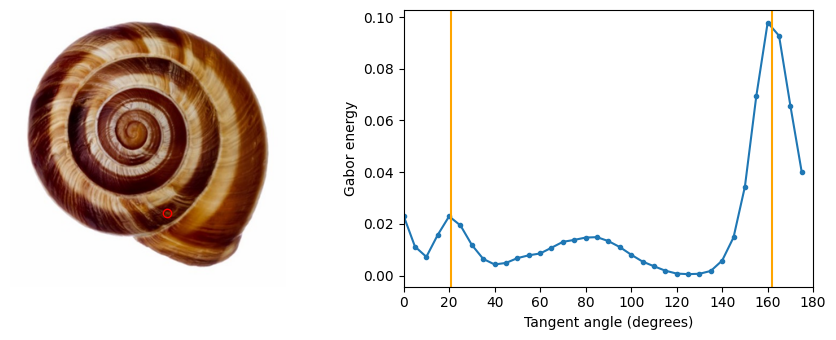

interactive(children=(IntSlider(value=0, description='site', max=304), Output()), _dom_classes=('widget-intera…

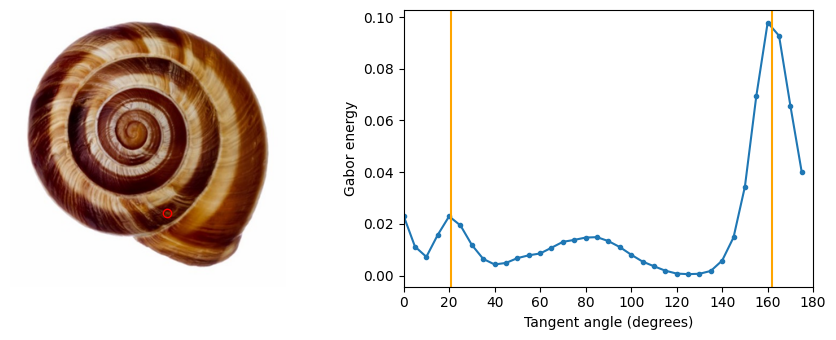

In [12]:
def show_response(site=0):
    tangent_bins = (-(np.arange(36) * np.pi / 36 + np.pi / 2)) % np.pi
    order = np.argsort(tangent_bins)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    axes[0].imshow(rgb)
    axes[0].plot(*pixel_xy[site], "ro", fillstyle="none")
    axes[0].axis("off")
    axes[1].plot(np.degrees(tangent_bins[order]), spectra[order, site], ".-")
    for angle in angles[site, valid[site]]:
        axes[1].axvline(np.degrees(angle), color="orange")
    axes[1].set(xlabel="Tangent angle (degrees)", ylabel="Gabor energy", xlim=(0, 180))
    plt.tight_layout()
    plt.show()

interact(show_response, site=IntSlider(min=0, max=len(pixel_xy)-1, value=0))
show_response(0)  # Ordinary saved plot as well as the interactive view.


## 5. Select one actual candidate using spatial smoothness

The selector fits a smooth Gaussian-RBF field to doubled polar-relative angles. It alternates a ridge solve and candidate choice, balancing directional agreement against an energy penalty:
\[
\|q_i-z(\phi_{ij}-\theta_i)\|^2+0.5\log(E_{i,\max}/E_{ij}),\qquad
z(a)=(\cos2a,\sin2a).
\]
Here $\theta_i$ is the site's spatial polar angle. Use the established bandwidth $60/433$, ridge 0.01, 128 landmarks, and 32 starts.
The selected observation remains an **exact measured candidate**. The smooth selector prediction is shown separately.


Canonicalize the unordered candidates, normalize their energies, and construct deterministic spatial landmarks.


In [13]:
SELECTOR_H = 60.0 / 433.0

SELECTOR_RIDGE = .01

SELECTOR_ETA = .5

def canonical_candidates(angles, valid, energy):
    """Sort local candidates by angle and normalize their measured energies."""
    angles = np.where(valid, np.mod(angles, np.pi), np.nan)
    valid = valid & np.isfinite(angles)
    if not valid.any(axis=1).all():
        raise ValueError("Selector needs at least one accepted candidate per site")
    if not (energy[valid] > 0).all():
        raise ValueError("Valid Gabor candidates require positive measured energy")
    strengths = np.where(valid, energy, 0.)
    strengths = strengths / strengths.max(axis=1)[:, None]
    order = np.argsort(np.where(valid, angles, np.inf), axis=1)
    return (np.take_along_axis(angles, order, axis=1),
            np.take_along_axis(valid, order, axis=1),
            np.take_along_axis(strengths, order, axis=1), order)

def landmarks(xy, maximum=128):
    """Choose deterministic farthest-point Cartesian basis centers."""
    if len(xy) <= maximum:
        return xy.copy()
    selected = np.empty(maximum, dtype=int)
    selected[0] = int(np.argmax(np.sum((xy - xy.mean(axis=0)) ** 2, axis=1)))
    distance = np.full(len(xy), np.inf)
    for i in range(1, maximum):
        distance = np.minimum(distance, np.sum((xy - xy[selected[i - 1]]) ** 2, axis=1))
        selected[i] = int(np.argmax(distance))
    return xy[selected]


Construct the centered RBF basis and doubled-angle targets used by the selector.


In [14]:
def gaussian_basis(xy, centers, bandwidth=SELECTOR_H):
    """Evaluate the Cartesian Gaussian basis in normalized coordinate units."""
    return np.exp(-cdist(xy, centers, "sqeuclidean") / (2 * bandwidth ** 2))

def embed(angles):
    """Represent a headless direction by its doubled-angle unit vector."""
    return np.column_stack((np.cos(2 * angles), np.sin(2 * angles)))

def selector_setup(xy, angles, valid, energy, maximum, bandwidth, ridge, eta):
    """Prepare polar-relative targets and the centered ridge factorization."""
    angles, valid, strengths, order = canonical_candidates(angles, valid, energy)
    n = len(xy)
    theta = np.arctan2(xy[:, 1], xy[:, 0])
    pitch = np.where(valid, angles - theta[:, None], 0.)
    z = np.stack((np.cos(2 * pitch), np.sin(2 * pitch)), axis=-1)
    cost = eta * np.log(1 / np.maximum(strengths, 1e-300))
    cost[~valid] = np.inf
    centers = landmarks(xy, maximum)
    psi = gaussian_basis(xy, centers, bandwidth)
    feature_mean = psi.mean(axis=0)
    x = psi - feature_mean
    gram = np.einsum("ni,nj->ij", x, x) / n
    gram.flat[::len(centers) + 1] += ridge
    return dict(n=n, index=np.arange(n), theta=theta, angles=angles, valid=valid,
                z=z, cost=cost, order=order, centers=centers,
                feature_mean=feature_mean, x=x, factor=cho_factor(gram, lower=True),
                bandwidth=bandwidth, ridge=ridge, eta=eta)


Create the same 32 deterministic and seeded initial assignments, then alternate ridge fitting with candidate selection.


In [15]:
def selector_starts(state, count=32, seed=42):
    """Build the original two endpoint, ten directional, and random starts."""
    n, theta = state["n"], state["theta"]
    starts = [np.zeros(n, dtype=int), state["valid"][:, 1].astype(int)]
    directions = [np.deg2rad(d) for d in (0, 30, 60, 90, 120, 150)]
    directions += [theta + np.deg2rad(d) for d in (0, 30, -30, 90)]
    for angle in directions:
        pitch = np.broadcast_to(angle, (n,)) - theta
        starts.append(nearest_candidates(state, embed(pitch)))
    rng = np.random.default_rng(seed)
    for _ in range(max(0, count - len(starts))):
        assignment = rng.integers(0, 2, n)
        assignment[~state["valid"][:, 1]] = 0
        starts.append(assignment)
    return starts[:count]

def solve_selector(state, assignment):
    """Solve the two ridge regressions for a fixed candidate assignment."""
    target = state["z"][state["index"], assignment]
    mean = target.mean(axis=0)
    rhs = np.einsum("ni,nj->ij", state["x"], target - mean) / state["n"]
    coefficients = cho_solve(state["factor"], rhs)
    q = np.einsum("ni,ij->nj", state["x"], coefficients) + mean
    return coefficients, mean, q

def nearest_candidates(state, q):
    """Assign only measured candidates, balancing agreement and peak energy."""
    return np.argmin(np.sum((q[:, None, :] - state["z"]) ** 2, axis=-1)
                     + state["cost"], axis=1)


Run the alternating updates until the candidate assignment stops changing; retain the best initial start.


In [16]:
def run_selector_start(state, assignment, start):
    """Alternate ridge fitting and candidate choice until assignments stop."""
    assignment = assignment.copy()
    history = []
    for iteration in range(250):
        coefficients, mean, q = solve_selector(state, assignment)
        new = nearest_candidates(state, q)
        objective = float(np.mean(np.sum((q - state["z"][state["index"], new]) ** 2,
                                         axis=1) + state["cost"][state["index"], new])
                          + state["ridge"] * np.sum(coefficients ** 2))
        if history and objective > history[-1] + 1e-11:
            raise ArithmeticError("Selector objective increased")
        history.append(objective)
        if np.array_equal(new, assignment):
            break
        assignment = new
    else:
        raise RuntimeError("Selector failed to converge in 250 iterations")
    return dict(start=start, objective=objective, iterations=iteration + 1,
                history=history, assignment=assignment.copy(),
                coefficients=coefficients, target_mean=mean)

def select_directions(xy, angles, valid, energies, max_centers=128, starts=32,
                      seed=0, bandwidth=SELECTOR_H, ridge=SELECTOR_RIDGE,
                      eta=SELECTOR_ETA):
    """Return model, exact measured angles, original slots, and diagnostics.

    Pass accepted sites only. Use seed=42 to reproduce the archived selector;
    other settings define an exploratory selection. Smooth predictions are
    returned separately by selector_predict and never become observations.
    """
    xy, angles = np.asarray(xy, float), np.asarray(angles, float)
    valid, energies = np.asarray(valid, bool), np.asarray(energies, float)
    if xy.ndim != 2 or xy.shape[1] != 2 or not np.isfinite(xy).all():
        raise ValueError("xy must be a finite N x 2 Cartesian array")
    if len(xy) < 1 or angles.shape != (len(xy), 2) or valid.shape != angles.shape or energies.shape != angles.shape:
        raise ValueError("Two candidate slots per coordinate are required")
    bandwidth, ridge, eta = float(bandwidth), float(ridge), float(eta)
    starts, seed = int(starts), int(seed)
    if bandwidth <= 0 or ridge <= 0 or eta < 0 or starts < 1 or max_centers < 1:
        raise ValueError("Positive bandwidth/ridge/counts and nonnegative eta required")
    state = selector_setup(xy, angles, valid, energies, max_centers, bandwidth, ridge, eta)
    records = [run_selector_start(state, assignment, start)
               for start, assignment in enumerate(selector_starts(state, starts, seed))]
    best = min(records, key=lambda row: row["objective"])
    model = dict(centers=state["centers"], feature_mean=state["feature_mean"],
                 coefficients=best["coefficients"], target_mean=best["target_mean"],
                 bandwidth=bandwidth, ridge=ridge, eta=eta)
    target = state["angles"][state["index"], best["assignment"]]
    assignment = state["order"][state["index"], best["assignment"]]
    diagnostic = dict(best_start=best["start"], objective=best["objective"],
                      starts=[{k: row[k] for k in ("start", "objective", "iterations", "history")}
                              for row in records], all_starts_converged=True,
                      seed=seed, bandwidth=bandwidth, ridge=ridge, eta=eta,
                      initialization_count=starts)
    return model, target, assignment, diagnostic


Rotate the selector prediction back into global Cartesian angles. The final helper applies a training-only selector to held-out candidates.


In [17]:
def selector_predict(model, xy):
    """Predict smooth doubled global angles, rotating once from polar pitch."""
    q = (np.einsum("ni,ij->nj", gaussian_basis(xy, model["centers"], model.get("bandwidth", SELECTOR_H)) - model["feature_mean"],
                   model["coefficients"]) + model["target_mean"])
    rotation = 2 * np.arctan2(xy[:, 1], xy[:, 0])
    a, b = q[:, 0].copy(), q[:, 1].copy()
    return np.column_stack((np.cos(rotation) * a - np.sin(rotation) * b,
                            np.sin(rotation) * a + np.cos(rotation) * b))

def choose_test_candidate(q_global, angles, valid, energy, eta=SELECTOR_ETA):
    """Assign held-out measured peaks from a training-only smooth prediction."""
    canonical, usable, strengths, order = canonical_candidates(angles, valid, energy)
    safe = np.where(usable, canonical, 0.)
    z = np.stack((np.cos(2 * safe), np.sin(2 * safe)), axis=-1)
    cost = eta * np.log(1 / np.maximum(strengths, 1e-300))
    distance = np.sum((q_global[:, None, :] - z) ** 2, axis=-1) + cost
    distance[~usable] = np.inf
    assignment = np.argmin(distance, axis=1)
    rows = np.arange(len(angles))
    return canonical[rows, assignment], order[rows, assignment]


In [18]:
selector, selected_angles, selected_slots, selection_info = select_directions(
    xy[accepted], angles[accepted], valid[accepted], peak_energy[accepted],
    bandwidth=60/433, ridge=0.01, eta=0.5, max_centers=128, starts=32, seed=42,
)
assert np.array_equal(selected_angles, angles[accepted, selected_slots])
q = selector_predict(selector, xy[accepted])
smooth_angles = 0.5 * np.arctan2(q[:, 1], q[:, 0])
print(len(selected_angles), "selected measured directions")


305 selected measured directions


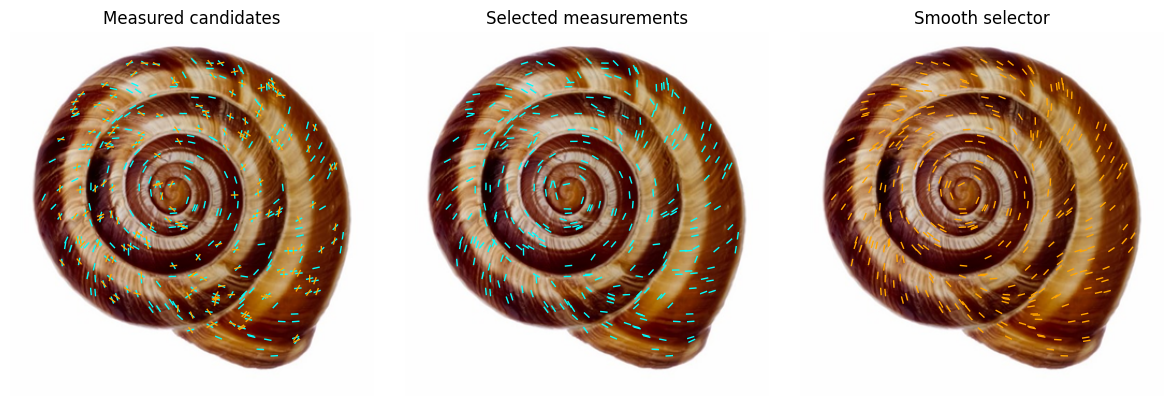

In [19]:
def draw_lines(ax, pixels, directions, color="cyan", length=7):
    keep = np.isfinite(directions)
    delta = length/2 * np.column_stack((np.cos(directions[keep]), -np.sin(directions[keep])))
    segments = np.stack((pixels[keep]-delta, pixels[keep]+delta), axis=1)
    ax.add_collection(LineCollection(segments, colors=color, linewidths=1))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax in axes:
    ax.imshow(rgb)
    ax.axis("off")
for slot, color in enumerate(("cyan", "orange")):
    draw_lines(axes[0], pixel_xy, np.where(valid[:, slot], angles[:, slot], np.nan), color)
draw_lines(axes[1], pixel_xy[accepted], selected_angles)
draw_lines(axes[2], pixel_xy[accepted], smooth_angles, "orange")
for ax, title in zip(axes, ["Measured candidates", "Selected measurements", "Smooth selector"]):
    ax.set_title(title)
plt.tight_layout()
plt.show()


## 6. Fit the line field

Fit the parametric spiral, Gaussian RBF, RBF × spatial von Mises, and polynomial models to the selected measurements.
The likelihood is axial von Mises in polar-relative pitch; feature coefficients have Gaussian priors.
These fast fits are **optimization estimates**, with explicit fixed settings. They are not posterior means or credible intervals.
The completed Bayesian results are loaded separately in the next section.


Let $\theta$ be spatial polar angle and $\psi=\phi-\theta$ be pitch. The latent vector $f$ gives density $\exp(f^T z(\psi))/(\pi I_0(\|f\|))$, where $I_0$ is the modified Bessel function. Its norm is likelihood concentration, not posterior uncertainty. The following geometry and basis functions define that model explicitly.


In [20]:
MODEL_LABELS = {
    "parametric": "Parametric spiral",
    "gaussian_rbf": "Gaussian RBF",
    "multiplicative_rbf_vm": "RBF × von Mises",
    "polynomial": "Polynomial",
}

def axial_delta(a, b):
    """Signed shortest axial difference in [-pi/2, pi/2]."""
    return 0.5 * np.arctan2(np.sin(2 * (a - b)), np.cos(2 * (a - b)))

def _positions(xy):
    xy = np.asarray(xy, dtype=float)
    if xy.ndim != 2 or xy.shape[1] != 2 or not np.isfinite(xy).all():
        raise ValueError("xy must be a finite (n, 2) array")
    return xy

def _landmarks(xy, maximum):
    """Deterministic farthest-point basis selection used by the saved models."""
    if len(xy) <= maximum:
        return xy.copy()
    selected = np.empty(maximum, dtype=int)
    selected[0] = np.argmax(np.sum((xy - xy.mean(0)) ** 2, axis=1))
    distance = np.full(len(xy), np.inf)
    for i in range(1, maximum):
        distance = np.minimum(distance, np.sum((xy - xy[selected[i - 1]]) ** 2, axis=1))
        selected[i] = np.argmax(distance)
    return xy[selected].copy()


In [21]:
def _affinity(xy, centers, bandwidth, kappa):
    """Peak-normalized Cartesian RBF × spatial-angle von Mises basis."""
    distance2 = np.sum((xy[:, None] - centers[None]) ** 2, axis=-1)
    theta = np.arctan2(xy[:, 1], xy[:, 0])
    theta_c = np.arctan2(centers[:, 1], centers[:, 0])
    return np.exp(-distance2 / (2 * bandwidth ** 2)
                  + kappa * (np.cos(theta[:, None] - theta_c[None]) - 1))

def _polynomial_features(xy, degree):
    """Nonconstant exact features of (1 + x dot y)**degree in two dimensions."""
    terms = [(a, total - a) for total in range(1, degree + 1)
             for a in range(total, -1, -1)]
    if not terms:
        return np.empty((len(xy), 0))
    exponents = np.asarray(terms, dtype=int)
    multipliers = np.asarray([
        math.sqrt(math.comb(degree, a + b) * math.comb(a + b, a))
        for a, b in terms
    ])
    with np.errstate(over="raise", invalid="raise"):
        return np.prod(xy[:, None, :] ** exponents[None], axis=-1) * multipliers


The coefficient objective includes the exact axial von Mises likelihood and standard-normal whitened priors. Training-centered features have prior standard deviations 2 for the intercept and 1 for other coefficients.


In [22]:
def directional_objective(flat, design, targets):
    """Negative log VM posterior/gradient; design includes prior scales."""
    xi = np.asarray(flat).reshape(design.shape[1], 2)
    q = design @ xi
    radius = np.linalg.norm(q, axis=1)
    log_i0 = np.log(i0e(radius)) + radius
    loss = (0.5 * np.sum(xi ** 2)
            + np.sum(log_i0 + np.log(np.pi) - np.sum(q * targets, axis=1)))
    ratio = i1e(radius) / i0e(radius)
    ratio_over_radius = np.divide(ratio, radius, out=np.full_like(radius, 0.5),
                                  where=radius > 1e-12)
    gradient = xi + design.T @ (q * ratio_over_radius[:, None] - targets)
    return float(loss), gradient.ravel()


The spiral uses $\phi=\theta+\operatorname{atan2}(-\sin\gamma,\cos\gamma\,r^p)$, with $p\sim\mathrm{Uniform}(-3,3)$, axial-uniform $\gamma$, and $\rho\sim\mathrm{Rayleigh}(2)$. The objective below includes the Jacobians for $p=3\tanh z_p$ and $\rho=\exp z_\rho$. Its optimization estimate is a mode in those computational coordinates; it is not the archived posterior mean.


In [23]:
def parametric_objective(position, xy, target):
    """Transformed posterior/gradient: p=3tanh(zp), rho=exp(zrho), with Jacobians."""
    zp, gamma, zrho = np.asarray(position, dtype=float)
    if not np.isfinite(position).all() or abs(zrho) > 300 or abs(zp) > 300:
        return np.inf, np.zeros(3)
    theta = np.arctan2(xy[:, 1], xy[:, 0])
    log_radius = np.log(np.linalg.norm(xy, axis=1))
    p = 3 * np.tanh(zp)
    dp = 3 * (1 - np.tanh(zp) ** 2)
    rho = np.exp(zrho)
    t = np.exp(p * log_radius)
    sine, cosine = np.sin(gamma), np.cos(gamma)
    denominator = (cosine * t) ** 2 + sine ** 2
    angle = theta + np.arctan2(-sine, cosine * t)
    difference = 2 * (target - angle)
    cos_difference = np.cos(difference)
    loglike = np.sum(rho * cos_difference) - len(xy) * (
        np.log(i0e(rho)) + rho + np.log(np.pi))
    logprior = (2 * (np.log(2) - np.logaddexp(zp, -zp)) - np.log(2)
                + 2 * zrho - np.log(4) - rho * rho / 8 - np.log(np.pi))
    angle_gradient = 2 * rho * np.sin(difference)
    gp = (np.sum(angle_gradient * sine * cosine * t * log_radius / denominator)
          * dp - 2 * np.tanh(zp))
    gg = np.sum(angle_gradient * (-t / denominator))
    grho = (np.sum(cos_difference) - len(xy) * i1e(rho) / i0e(rho)) * rho
    grho += 2 - rho * rho / 4
    return float(-loglike - logprior), -np.array([gp, gg, grho])


Use multiple deterministic starting points for the spiral; initialize the feature models using zero and ridge estimates, and optimize the same posterior objectives.


In [24]:
def _fit_parametric(xy, target, config):
    objective = lambda state: parametric_objective(state, xy, target)
    grid = [(objective(np.array([np.arctanh(p / 3), g, np.log(2)]))[0],
             np.array([np.arctanh(p / 3), g, np.log(2)]))
            for p in np.linspace(-2.8, 2.8, 13)
            for g in np.linspace(-np.pi / 2, np.pi / 2, 36, endpoint=False)]
    grid.sort(key=lambda item: item[0])
    starts = [grid[0][1]]
    for _, candidate in grid[1:]:
        if len(starts) >= int(config.get("parametric_starts", 12)):
            break
        if all(np.linalg.norm(candidate[[0, 2]] - old[[0, 2]])
               + abs(axial_delta(candidate[1], old[1])) > 0.5 for old in starts):
            starts.append(candidate)
    starts.extend(np.array([0, g, np.log(2)]) for g in (-1.4, -0.7, 0, 0.7, 1.4))
    results = [minimize(objective, state, jac=True, method="L-BFGS-B",
                        bounds=((-12, 12), (None, None), (-8, 5)),
                        options={"maxiter": 1500, "ftol": 1e-12, "gtol": 1e-7})
               for state in starts]
    best = min(results, key=lambda result: result.fun)
    return dict(family="parametric", p=float(3 * np.tanh(best.x[0])),
                gamma=float((best.x[1] + np.pi / 2) % np.pi - np.pi / 2),
                rho=float(np.exp(best.x[2])), objective=float(best.fun),
                success=bool(best.success), message=str(best.message),
                estimate="Transformed-coordinate posterior mode preview",
                training_count=len(xy), config=dict(config))


In [25]:
def _fit_directional(xy, target, family, config):
    centers = _landmarks(xy, int(config["max_centers"]))
    kappa = float(config["kappa"]) if family == "multiplicative_rbf_vm" else 0.0
    features = (_polynomial_features(xy, int(config["degree"]))
                if family == "polynomial" else
                _affinity(xy, centers, float(config["bandwidth"]), kappa))
    feature_mean = features.mean(0)
    design_unscaled = np.column_stack([np.ones(len(xy)), features - feature_mean])
    prior_sd = np.r_[config["tau_intercept"],
                     np.full(features.shape[1], config["tau_beta"])]
    design = design_unscaled * prior_sd
    theta = np.arctan2(xy[:, 1], xy[:, 0])
    targets = np.column_stack([np.cos(2 * (target - theta)),
                               np.sin(2 * (target - theta))])
    centered = design_unscaled[:, 1:]
    gram = centered.T @ centered / len(xy)
    gram.flat[::len(gram) + 1] += float(config["initialization_ridge"])
    target_mean = targets.mean(0)
    coefficients = cho_solve(cho_factor(gram, lower=True),
                              centered.T @ (targets - target_mean) / len(xy))
    pilot = 3 * np.vstack([target_mean, coefficients]) / prior_sd[:, None]
    objective = lambda state: directional_objective(state, design, targets)
    results = [minimize(objective, start.ravel(), jac=True, method="L-BFGS-B",
                        options={"maxiter": 1500, "ftol": 1e-12, "gtol": 1e-7})
               for start in (np.zeros_like(pilot), pilot)]
    best = min(results, key=lambda result: result.fun)
    return dict(family=family, config=dict(config), centers=centers,
                kappa=kappa, feature_mean=feature_mean, prior_sd=prior_sd,
                xi=best.x.reshape(-1, 2), objective=float(best.fun),
                success=bool(best.success), message=str(best.message),
                estimate="Whitened-coefficient posterior mode preview",
                training_count=len(xy))


These last two functions fit all four families and evaluate a fitted field. Settings remain fixed by the explicit call below; no held-out tuning or posterior sampling is hidden here.


In [26]:
def fit_models(xy, target, config=None):
    """Fit four point estimates at fixed settings; caller manages train/test splits."""
    xy = _positions(xy)
    target = np.asarray(target, dtype=float)
    if not len(xy) or target.shape != (len(xy),) or not np.isfinite(target).all():
        raise ValueError("target must contain one finite angle per nonempty xy row")
    if np.any(np.linalg.norm(xy, axis=1) <= 1e-12):
        raise ValueError("Polar direction is undefined at the fixed center")
    settings = dict(bandwidth=0.3, kappa=2.0, degree=4, max_centers=32,
                    tau_intercept=2.0, tau_beta=1.0, initialization_ridge=1e-3,
                    parametric_starts=12)
    settings.update({} if config is None else config)
    for key in ("bandwidth", "tau_intercept", "tau_beta", "initialization_ridge"):
        if not np.isfinite(settings[key]) or settings[key] <= 0:
            raise ValueError(f"{key} must be positive and finite")
    if not np.isfinite(settings["kappa"]) or settings["kappa"] < 0:
        raise ValueError("kappa must be nonnegative and finite")
    for key, minimum in (("degree", 0), ("max_centers", 1), ("parametric_starts", 1)):
        if isinstance(settings[key], (bool, np.bool_)) or not isinstance(
                settings[key], (int, np.integer)) or settings[key] < minimum:
            raise ValueError(f"{key} must be an integer >= {minimum}")
    target = np.mod(target, np.pi)
    fits = {"parametric": _fit_parametric(xy, target, settings)}
    for family in ("gaussian_rbf", "multiplicative_rbf_vm", "polynomial"):
        fits[family] = _fit_directional(xy, target, family, settings)
    return fits


In [27]:
def predict_model(fit, xy):
    """Return (axial angle, likelihood concentration); zero fields return NaN angles."""
    xy = _positions(xy)
    theta = np.arctan2(xy[:, 1], xy[:, 0])
    noncentral = np.linalg.norm(xy, axis=1) > 1e-12
    if fit["family"] == "parametric":
        radius = np.maximum(np.linalg.norm(xy, axis=1), 1e-12)
        angle = theta + np.arctan2(-np.sin(fit["gamma"]),
                                  np.cos(fit["gamma"]) * radius ** fit["p"])
        return np.where(noncentral, np.mod(angle, np.pi), np.nan), np.full(len(xy), fit["rho"])
    config = fit["config"]
    features = (_polynomial_features(xy, int(config["degree"]))
                if fit["family"] == "polynomial" else
                _affinity(xy, fit["centers"], config["bandwidth"], fit["kappa"]))
    design = np.column_stack([np.ones(len(xy)), features - fit["feature_mean"]])
    q = (design * fit["prior_sd"]) @ fit["xi"]
    strength = np.linalg.norm(q, axis=1)
    angle = np.mod(theta + 0.5 * np.arctan2(q[:, 1], q[:, 0]), np.pi)
    valid = noncentral & np.isfinite(q).all(1) & (strength > 1e-12)
    return np.where(valid, angle, np.nan), strength


In [28]:
fits = fit_models(
    xy[accepted], selected_angles,
    config=dict(bandwidth=0.30, kappa=2.0, degree=4, max_centers=32),
)
for name, fit in fits.items():
    print(MODEL_LABELS[name], "· optimizer converged:", fit["success"])


Parametric spiral · optimizer converged: True
Gaussian RBF · optimizer converged: True
RBF × von Mises · optimizer converged: True
Polynomial · optimizer converged: True


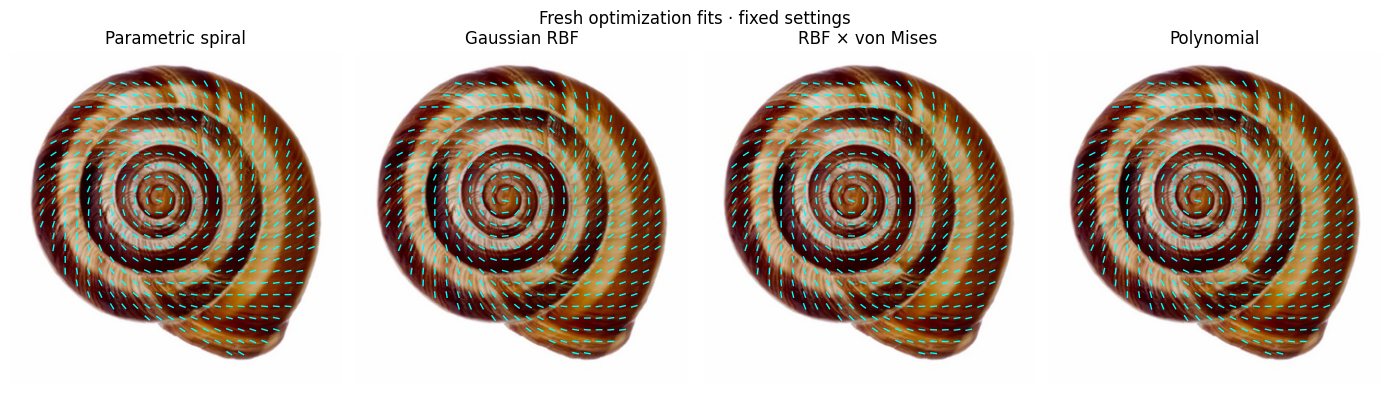

In [29]:
# Evaluate every fitted model on the same geometry-only plotting grid.
gy, gx = np.mgrid[8:mask.shape[0]:12, 8:mask.shape[1]:12]
grid_pixels = np.column_stack((gx.ravel(), gy.ravel()))
grid_pixels = grid_pixels[mask[grid_pixels[:, 1], grid_pixels[:, 0]]]
grid_xy = (grid_pixels-center) * [1, -1] / scale

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (name, fit) in zip(axes, fits.items()):
    predicted_angles, concentration = predict_model(fit, grid_xy)
    ax.imshow(rgb)
    draw_lines(ax, grid_pixels, predicted_angles)
    ax.set_title(MODEL_LABELS[name])
    ax.axis("off")
fig.suptitle("Fresh optimization fits · fixed settings")
plt.tight_layout()
plt.show()


## 7. Completed Bayesian results and uncertainty

Read the existing streamline files directly. Nothing is embedded or decoded. The saved curves use the original approved mask and settings, even if you changed the live workflow above.
Color is the **pointwise latent 95% angular-deviation radius**, conditional on mask, center, candidate selection, and tuning. It is not a predictive interval or simultaneous whole-curve band. Saved numerical traces can overlap visually.


In [30]:
is_sem = image.startswith("front_")
result_folder = ROOT / "output" / (
    "sem-front-four-model-20261104" if is_sem else "full-mask-four-model-20261104"
)
baseline_paths = (result_folder / "trajectories" if is_sem else
                  ROOT / "output/figures/mse-rosette-mask-revision/trajectories")
with np.load(baseline_paths / f"{image}.npz") as source:
    saved_curves = dict(source)
with np.load(result_folder / "trajectories" / f"{image}-polynomial.npz") as source:
    polynomial_curves = dict(source)


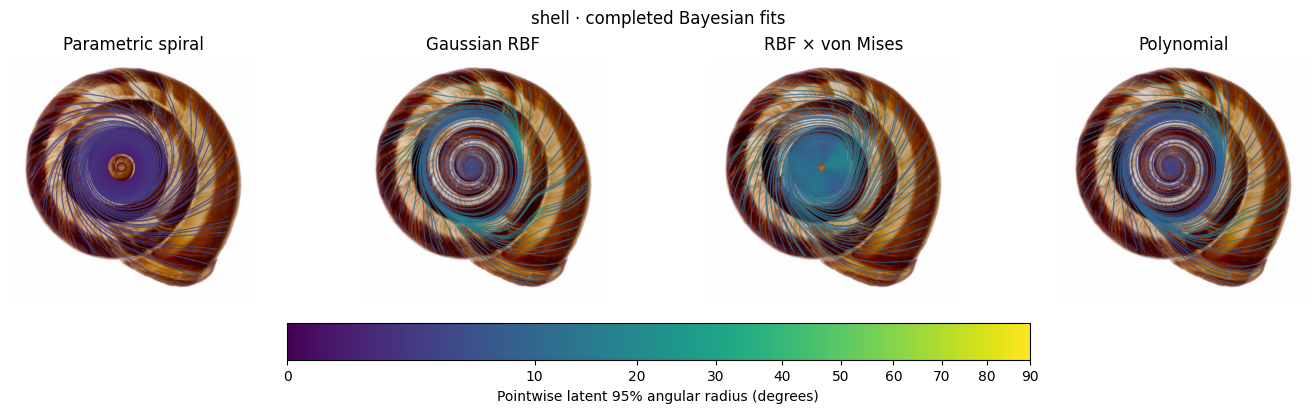

In [31]:
def draw_saved_field(ax, model):
    archive = polynomial_curves if model == "polynomial" else saved_curves
    vertices = archive[model + "__vertices"]
    offsets = archive[model + "__offsets"]
    radii = archive[model + "__radius95_deg"]
    segments, colors = [], []
    for left, right in zip(offsets[:-1], offsets[1:]):
        path = vertices[left:right]
        segments.extend(np.stack((path[:-1], path[1:]), axis=1))
        colors.extend((radii[left:right-1] + radii[left+1:right]) / 2)
    ax.imshow(rgb)
    artist = LineCollection(segments, array=np.asarray(colors), cmap="viridis",
                            norm=PowerNorm(0.5, vmin=0, vmax=90), linewidths=0.8)
    ax.add_collection(artist)
    ax.set_title(MODEL_LABELS[model])
    ax.axis("off")
    return artist

fig, axes = plt.subplots(1, 4, figsize=(14, 4), layout="constrained")
for ax, model in zip(axes, MODEL_LABELS):
    artist = draw_saved_field(ax, model)
fig.colorbar(artist, ax=axes, orientation="horizontal", shrink=0.55,
             label="Pointwise latent 95% angular radius (degrees)")
fig.suptitle(image + " · completed Bayesian fits")
bayesian_figure = fig
plt.show()


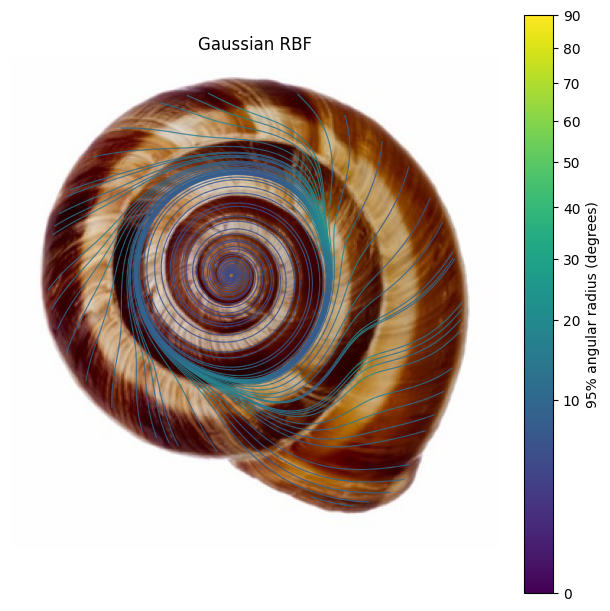

interactive(children=(Dropdown(description='model', index=1, options=('parametric', 'gaussian_rbf', 'multiplic…

<function __main__.inspect_model(model='gaussian_rbf')>

In [32]:
def inspect_model(model="gaussian_rbf"):
    fig, ax = plt.subplots(figsize=(6, 6), layout="constrained")
    artist = draw_saved_field(ax, model)
    fig.colorbar(artist, ax=ax, label="95% angular radius (degrees)")
    plt.show()

interact(inspect_model, model=list(MODEL_LABELS))


## 8. Held-out comparison across all eight images

Load each saved per-site error array and average it. All four models share fold-specific selected measured targets; every site was held out once.
The archived 90° penalty for invalid predictions is already included. These scores come from the completed nested Bayesian analysis, not the live full-data optimization above.


,Parametric spiral,Gaussian RBF,RBF × von Mises,Polynomial
image,,,,
shell,18.88,15.67,18.98,16.09
fern,10.40,7.34,8.13,7.15
particle_fig5,23.10,19.83,19.96,20.38
particle_fig27,22.89,19.47,22.03,21.52
rosette_ppt_13,29.12,26.84,27.96,29.66
rosette_ppt_14,32.70,27.27,30.56,31.84
front_ee_minus1_5_1500x,35.16,25.96,26.95,26.98
front_ee1_3_1500x,28.65,24.58,31.45,28.13


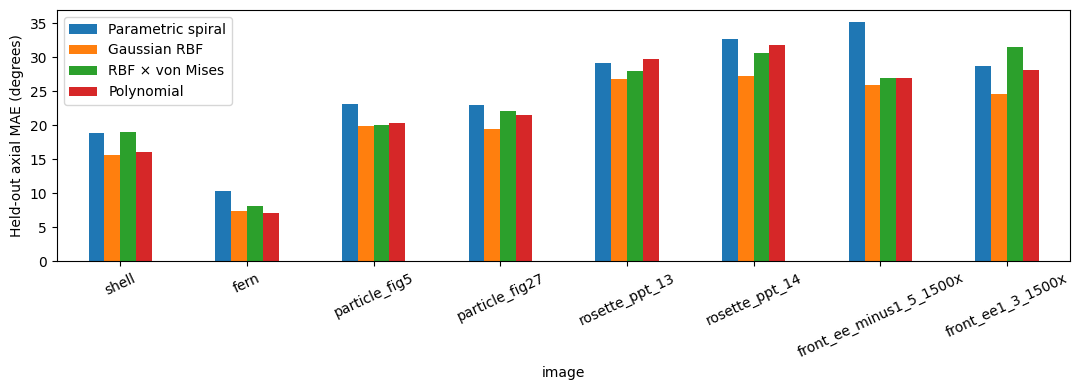

In [33]:
rows = []
for name in input_files:
    folder = ROOT / "output" / (
        "sem-front-four-model-20261104" if name.startswith("front_")
        else "full-mask-four-model-20261104"
    )
    with np.load(folder / "pooled-predictions" / f"{name}.npz") as predictions:
        scores = {label: predictions[model + "__error_deg"].mean()
                  for model, label in MODEL_LABELS.items()}
    rows.append(dict(image=name, **scores))
score_table = pd.DataFrame(rows).set_index("image")
display(score_table.round(2))
score_table.plot.bar(figsize=(11, 4), ylabel="Held-out axial MAE (degrees)", rot=25)
plt.tight_layout()
plt.show()


## 9. Save the plots and measurements

This final cell writes ordinary PNG/SVG/CSV files under `output/notebook-results/`. Rerun the workflow after changing the image or a parameter before exporting.


In [34]:
output = ROOT / "output/notebook-results" / image
output.mkdir(parents=True, exist_ok=True)
bayesian_figure.savefig(output / "bayesian-fields.png", dpi=180, bbox_inches="tight")
bayesian_figure.savefig(output / "bayesian-fields.svg", bbox_inches="tight")
score_table.to_csv(output / "heldout-mae-degrees.csv")
pd.DataFrame({
    "pixel_x": pixel_xy[accepted, 0], "pixel_y": pixel_xy[accepted, 1],
    "selected_angle_degrees": np.degrees(selected_angles), "candidate_slot": selected_slots,
}).to_csv(output / "selected-measurements.csv", index=False)
print("Saved to", output)


Saved to /Users/rishabhkumar/spiral-chirals/output/notebook-results/shell
